# SMOTE–GMM–XGBoost for Bipolar Disorder Detection

## 1. Imports

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from imblearn.over_sampling import SMOTE
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid", font="DejaVu Sans")

## 2. Configuration

In [44]:
# Update this path if Mentalillness.csv is stored elsewhere.
DATA_PATH = "Mentalillness.csv"

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_GMM_COMPONENTS = 4
N_SELECT_K = 30
SMOTE_K = 5

# Set either value to 0.0 to disable that simulated corruption.
MISSING_RATE = 0.10
SYMPTOM_FLIP_RATE = 0.06

# Fixed XGBoost parameters (the source script does not run grid search).
XGB_PARAMS = {
    "n_estimators": 80,
    "max_depth": 3,
    "learning_rate": 0.10,
    "subsample": 0.80,
    "colsample_bytree": 0.80,
    "reg_lambda": 5,
    "min_child_weight": 1,
}

LABEL_COL = "Bipolar disorder"
DROP_COLS = [
    "ID",
    "Bipolar disorder",
    "Schizophrenia",
    "Depression",
    "Anxiety disorder",
    "PTSD",
]

NAVY = "#0B3D5C"
TEAL = "#1A7A7A"
GOLD = "#C4A35A"
CORAL = "#C45C4A"
SLATE = "#4A5568"

## 3. Load and inspect the dataset

In [45]:
df = pd.read_csv(DATA_PATH)

if LABEL_COL not in df.columns:
    raise ValueError(f"Expected target column {LABEL_COL!r} was not found in the CSV.")

y = df[LABEL_COL].astype(int)
X = df.drop(columns=[col for col in DROP_COLS if col in df.columns]).astype(float)
raw_feature_names = list(X.columns)

print(f"Rows: {len(df):,}")
print(f"Raw features: {X.shape[1]}")
print(f"Bipolar disorder positive (1): {(y == 1).sum():,}")
print(f"Bipolar disorder negative (0): {(y == 0).sum():,}")

print("\\nFirst five rows of the feature matrix:")
display(X.head())

print("\\nTarget class distribution:")
display(y.value_counts().sort_index().rename(index={0: "Non-BD (0)", 1: "BD (1)"}).to_frame("Count"))

Rows: 3,753
Raw features: 53
Bipolar disorder positive (1): 2,909
Bipolar disorder negative (0): 844
\nFirst five rows of the feature matrix:


,Inflated self-esteem,Distractibility,Increase in goal-directed activity,Excessive involvement in activities with high potential for painful consequences,Racing thoughts,Decreased need for sleep,More talkative than usual,Disorganized thinking or speech,Intrusive memories or flashbacks,Diminished emotional expression,...,Angry outburst,Recklessness,Hypervigilance,Exaggerated startle response,Concentration issues,Sleep disturbance.1,More than one month of disturbance,The disturbance causes clinically significant distress,The disturbance is not substance induced,Intrusive memories or flashback
0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
2,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0
4,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0


\nTarget class distribution:


,Count
Bipolar disorder,
Non-BD (0),844
BD (1),2909


### 3.1 Optional simulated missing values and symptom flips

In [ ]:
# This reproduces the original script's synthetic corruption step.
rng = np.random.default_rng(RANDOM_STATE)
values = X.to_numpy(copy=True)

flip_mask = rng.random(values.shape) < SYMPTOM_FLIP_RATE
missing_mask = rng.random(values.shape) < MISSING_RATE

values[flip_mask] = 1.0 - values[flip_mask]
values[missing_mask] = np.nan

X = pd.DataFrame(values, columns=raw_feature_names, index=X.index)

print(f"Simulated missing rate: {MISSING_RATE:.0%}")
print(f"Simulated symptom-flip rate: {SYMPTOM_FLIP_RATE:.0%}")
print(f"Missing feature entries after simulation: {int(X.isna().sum().sum()):,}")

Simulated missing rate: 10%
Simulated symptom-flip rate: 6%
Missing feature entries after simulation: 19,828


## 4. Split the data before fitting preprocessing steps

In [47]:
X_train_df, X_test_df, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

y_train = np.asarray(y_train)
y_test = np.asarray(y_test)

print(f"Training rows: {len(y_train):,}")
print(f"Test rows: {len(y_test):,}")
print(f"Training positive rate: {y_train.mean():.3f}")
print(f"Test positive rate: {y_test.mean():.3f}")

Training rows: 3,002
Test rows: 751
Training positive rate: 0.775
Test positive rate: 0.775


## 5. Imputation, scaling, and feature selection

In [48]:
# Fit every preprocessing step on the training split only.
imputer = SimpleImputer(strategy="mean")
scaler = MinMaxScaler()
selector = SelectKBest(score_func=f_classif, k=min(N_SELECT_K, X_train_df.shape[1]))

X_train_imputed = imputer.fit_transform(X_train_df)
X_test_imputed = imputer.transform(X_test_df)

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

X_train = selector.fit_transform(X_train_scaled, y_train)
X_test = selector.transform(X_test_scaled)

selected_features = [
    name for name, keep in zip(raw_feature_names, selector.get_support()) if keep
]

print(f"Selected {len(selected_features)} of {len(raw_feature_names)} features.")
display(pd.DataFrame({"Selected feature": selected_features}))

Selected 30 of 53 features.


,Selected feature
0,Inflated self-esteem
1,Distractibility
2,Increase in goal-directed activity
3,Excessive involvement in activities with high ...
4,Racing thoughts
5,Decreased need for sleep
6,More talkative than usual
7,Intrusive memories or flashbacks
8,Diminished emotional expression
9,Hallucinations


## 6. Apply SMOTE to the training data only

In [49]:
smote = SMOTE(k_neighbors=SMOTE_K, random_state=RANDOM_STATE)
X_bal, y_bal = smote.fit_resample(X_train, y_train)

print(f"Before SMOTE: {len(y_train):,} training rows")
print(f"After SMOTE:  {len(y_bal):,} training rows")
print("Class counts after SMOTE:")
display(pd.Series(y_bal).value_counts().sort_index().rename(index={0: "Non-BD (0)", 1: "BD (1)"}).to_frame("Count"))

Before SMOTE: 3,002 training rows
After SMOTE:  4,654 training rows
Class counts after SMOTE:


,Count
Non-BD (0),2327
BD (1),2327


## 7. Fit the GMM and append posterior probabilities

In [50]:
gmm = GaussianMixture(
    n_components=N_GMM_COMPONENTS,
    covariance_type="diag",
    n_init=1,
    reg_covar=1e-6,
    random_state=RANDOM_STATE,
)
gmm.fit(X_bal)

# Each row receives four soft cluster-membership probabilities.
X_bal_gmm_probs = gmm.predict_proba(X_bal)
X_test_gmm_probs = gmm.predict_proba(X_test)

X_bal_aug = np.hstack([X_bal, X_bal_gmm_probs])
X_test_aug = np.hstack([X_test, X_test_gmm_probs])

enriched_feature_names = selected_features + [
    f"GMM_posterior_{i + 1}" for i in range(N_GMM_COMPONENTS)
]

print(f"Selected clinical features: {X_bal.shape[1]}")
print(f"GMM posterior features: {X_bal_gmm_probs.shape[1]}")
print(f"Enriched training matrix shape: {X_bal_aug.shape}")
print(f"Enriched test matrix shape: {X_test_aug.shape}")

Selected clinical features: 30
GMM posterior features: 4
Enriched training matrix shape: (4654, 34)
Enriched test matrix shape: (751, 34)


## 8. Train the proposed XGBoost model

In [51]:
xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=1,
    random_state=RANDOM_STATE,
    verbosity=0,
    **XGB_PARAMS,
)

xgb_model.fit(X_bal_aug, y_bal)
y_prob = xgb_model.predict_proba(X_test_aug)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

proposed_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
}

proposed_metrics_df = pd.DataFrame({
    "Metric": list(proposed_metrics.keys()),
    "Score": list(proposed_metrics.values()),
})
proposed_metrics_df["Score (%)"] = 100 * proposed_metrics_df["Score"]
display(proposed_metrics_df[["Metric", "Score", "Score (%)"]].round(4))

,Metric,Score,Score (%)
0,Accuracy,0.8881,88.8149
1,Precision,0.9235,92.3469
2,Recall,0.9330,93.2990
3,Specificity,0.7337,73.3728
4,F1-score,0.9282,92.8205
5,ROC-AUC,0.9093,90.9341


## 9. Learning curves

A separate XGBoost model is trained on a validation split of the SMOTE-balanced training data for plotting learning curves. This model is only for the learning-curve visualization; the final test metrics above come from `xgb_model`.

In [52]:
X_curve_train, X_curve_val, y_curve_train, y_curve_val = train_test_split(
    X_bal_aug,
    y_bal,
    test_size=0.15,
    stratify=y_bal,
    random_state=RANDOM_STATE,
)

curve_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric=["logloss", "error"],
    tree_method="hist",
    n_jobs=1,
    random_state=RANDOM_STATE,
    verbosity=0,
    **XGB_PARAMS,
)

curve_model.fit(
    X_curve_train,
    y_curve_train,
    eval_set=[(X_curve_train, y_curve_train), (X_curve_val, y_curve_val)],
    verbose=False,
)
curve_results = curve_model.evals_result()

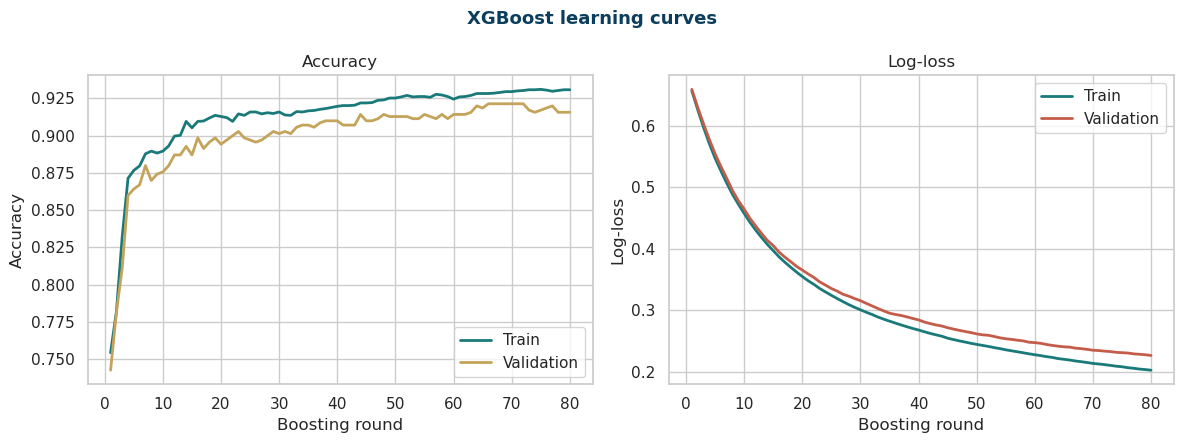

In [53]:
train_loss = curve_results["validation_0"]["logloss"]
val_loss = curve_results["validation_1"]["logloss"]
train_accuracy = [1 - error for error in curve_results["validation_0"]["error"]]
val_accuracy = [1 - error for error in curve_results["validation_1"]["error"]]
rounds = range(1, len(train_loss) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(rounds, train_accuracy, color=TEAL, linewidth=2, label="Train")
axes[0].plot(rounds, val_accuracy, color=GOLD, linewidth=2, label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Boosting round")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(rounds, train_loss, color=TEAL, linewidth=2, label="Train")
axes[1].plot(rounds, val_loss, color=CORAL, linewidth=2, label="Validation")
axes[1].set_title("Log-loss")
axes[1].set_xlabel("Boosting round")
axes[1].set_ylabel("Log-loss")
axes[1].legend()

fig.suptitle("XGBoost learning curves", fontsize=13, color=NAVY, fontweight="bold")
fig.tight_layout()
plt.show()

## 10. Visualize GMM subgroups with PCA

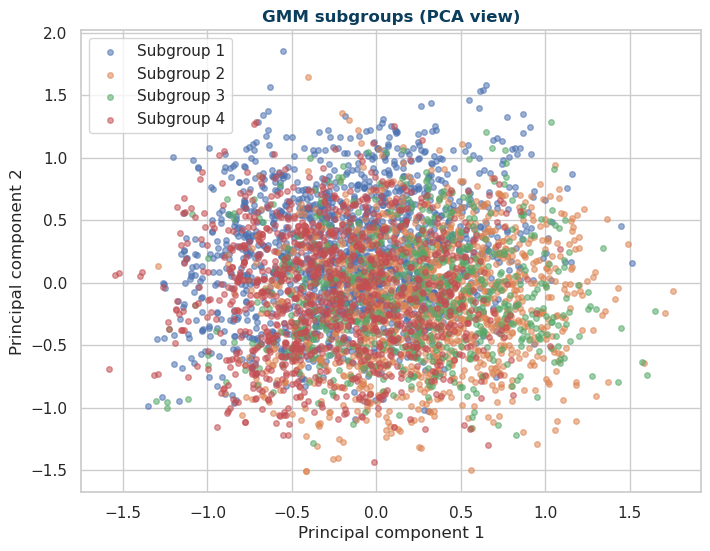

In [54]:
# PCA is used only to display the clusters in two dimensions.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_bal_pca = pca.fit_transform(X_bal)
gmm_cluster_labels = gmm.predict(X_bal)

fig, ax = plt.subplots(figsize=(8, 6))
for cluster_id in range(N_GMM_COMPONENTS):
    cluster_mask = gmm_cluster_labels == cluster_id
    ax.scatter(
        X_bal_pca[cluster_mask, 0],
        X_bal_pca[cluster_mask, 1],
        s=16,
        alpha=0.55,
        label=f"Subgroup {cluster_id + 1}",
    )
ax.set_xlabel("Principal component 1")
ax.set_ylabel("Principal component 2")
ax.set_title("GMM subgroups (PCA view)", color=NAVY, fontweight="bold")
ax.legend()
plt.show()

## 11. XGBoost feature importance

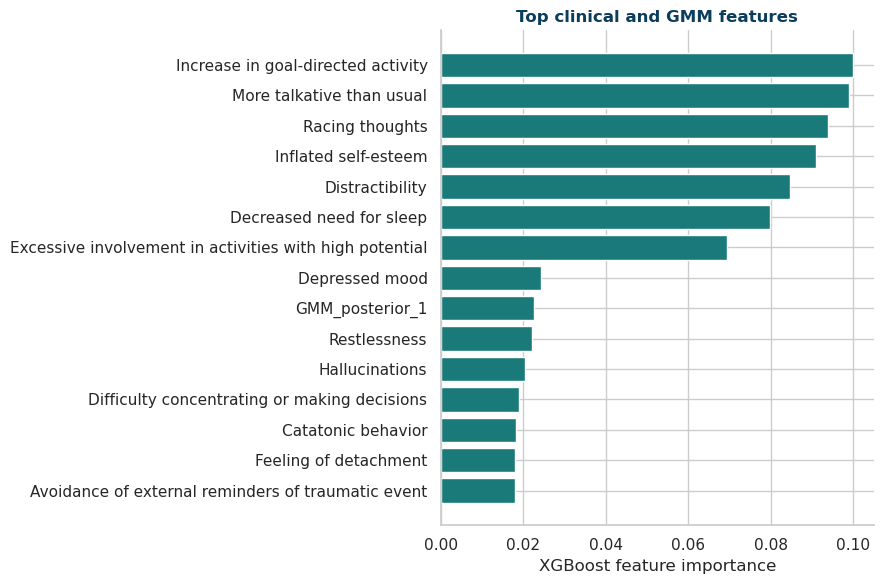

In [55]:
importance_values = xgb_model.feature_importances_
top_n = min(15, len(enriched_feature_names))
importance_order = np.argsort(importance_values)[::-1][:top_n]
plot_names = [enriched_feature_names[i][:55] for i in importance_order][::-1]
plot_values = importance_values[importance_order][::-1]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_names, plot_values, color=TEAL, edgecolor="white")
ax.set_xlabel("XGBoost feature importance")
ax.set_title("Top clinical and GMM features", color=NAVY, fontweight="bold")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

## 12. Confusion matrix

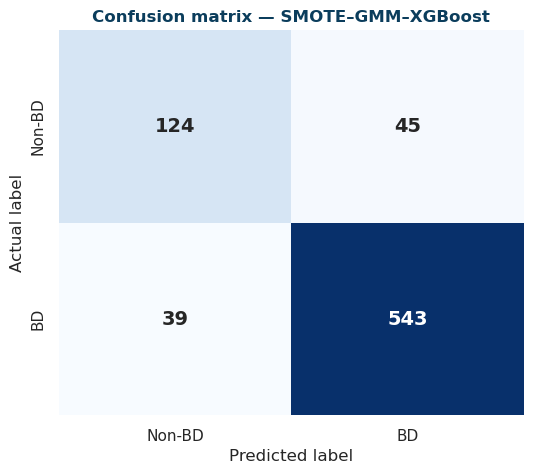

In [56]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Non-BD", "BD"],
    yticklabels=["Non-BD", "BD"],
    annot_kws={"size": 14, "weight": "bold"},
    ax=ax,
)
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_title("Confusion matrix — SMOTE–GMM–XGBoost", color=NAVY, fontweight="bold")
plt.show()

## 13. Proposed-model metric chart

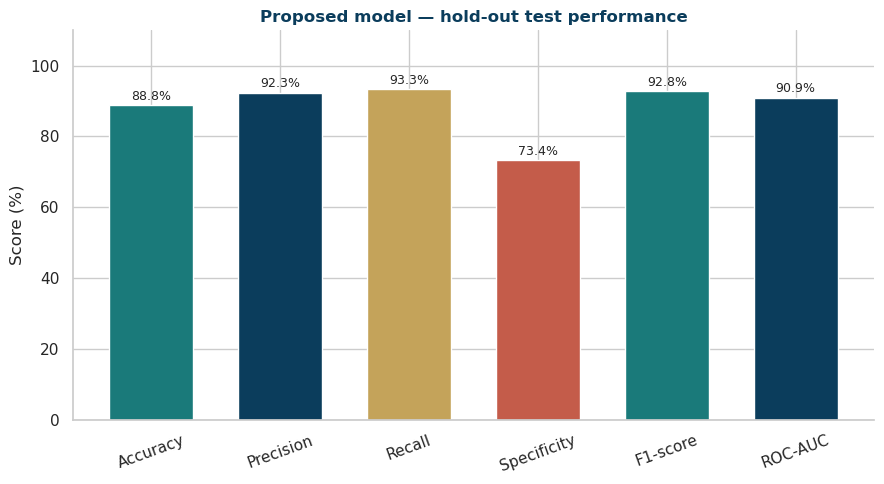

In [57]:
metric_names = list(proposed_metrics.keys())
metric_values_pct = [100 * proposed_metrics[name] for name in metric_names]
metric_colors = [TEAL, NAVY, GOLD, CORAL, TEAL, NAVY]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(metric_names, metric_values_pct, color=metric_colors, width=0.65, edgecolor="white")
ax.set_ylim(0, 110)
ax.set_ylabel("Score (%)")
ax.set_title("Proposed model — hold-out test performance", color=NAVY, fontweight="bold")
ax.tick_params(axis="x", rotation=20)
for bar, value in zip(bars, metric_values_pct):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 1.5, f"{value:.1f}%", ha="center", fontsize=9)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

## 14. Train baseline classifiers

The baseline classifiers use the same train/test split and the selected, imputed, scaled clinical features, but do not use SMOTE or GMM-augmented features. This follows the comparison setup in the original script.

In [58]:
baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    "SVM": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=80,
        max_depth=6,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

all_metrics = {"Proposed SMOTE–GMM–XGBoost": proposed_metrics}
roc_curves = {
    "Proposed SMOTE–GMM–XGBoost": (*roc_curve(y_test, y_prob)[:2], proposed_metrics["ROC-AUC"])
}

for model_name, model in baseline_models.items():
    model.fit(X_train, y_train)
    baseline_pred = model.predict(X_test)
    baseline_prob = model.predict_proba(X_test)[:, 1]

    baseline_cm = confusion_matrix(y_test, baseline_pred, labels=[0, 1])
    baseline_tn, baseline_fp, baseline_fn, baseline_tp = baseline_cm.ravel()

    baseline_metrics = {
        "Accuracy": accuracy_score(y_test, baseline_pred),
        "Precision": precision_score(y_test, baseline_pred, zero_division=0),
        "Recall": recall_score(y_test, baseline_pred, zero_division=0),
        "Specificity": baseline_tn / (baseline_tn + baseline_fp) if (baseline_tn + baseline_fp) else 0.0,
        "F1-score": f1_score(y_test, baseline_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, baseline_prob),
    }
    all_metrics[model_name] = baseline_metrics
    baseline_fpr, baseline_tpr, _ = roc_curve(y_test, baseline_prob)
    roc_curves[model_name] = (baseline_fpr, baseline_tpr, baseline_metrics["ROC-AUC"])

metrics_comparison = pd.DataFrame(all_metrics).T
display(metrics_comparison.round(4))

,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC
Proposed SMOTE–GMM–XGBoost,0.8881,0.9235,0.9330,0.7337,0.9282,0.9093
Logistic Regression,0.8855,0.9013,0.9570,0.6391,0.9283,0.9167
Decision Tree,0.8482,0.8611,0.9588,0.4675,0.9073,0.8445
SVM,0.8642,0.8727,0.9656,0.5148,0.9168,0.9043
Random Forest,0.8189,0.8132,0.9948,0.2130,0.8949,0.8980


## 15. ROC curves

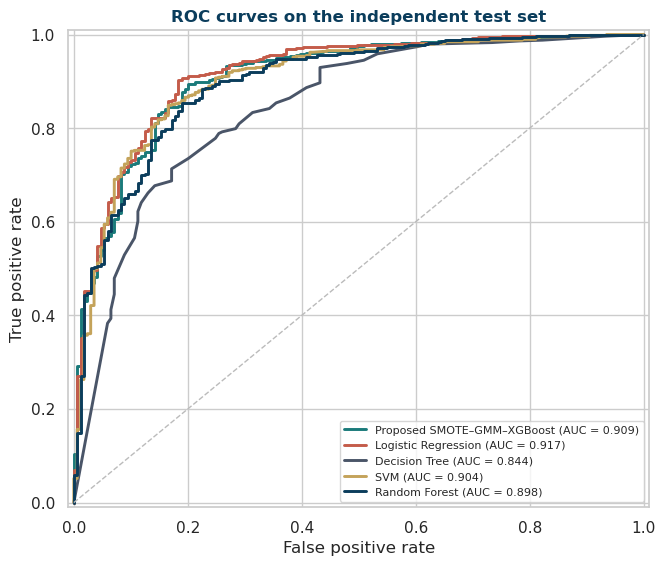

In [59]:
roc_colors = {
    "Proposed SMOTE–GMM–XGBoost": TEAL,
    "Random Forest": NAVY,
    "SVM": GOLD,
    "Logistic Regression": CORAL,
    "Decision Tree": SLATE,
}

fig, ax = plt.subplots(figsize=(7.5, 6.2))
for model_name, (fpr_values, tpr_values, auc_value) in roc_curves.items():
    ax.plot(
        fpr_values,
        tpr_values,
        linewidth=2.1,
        color=roc_colors.get(model_name, SLATE),
        label=f"{model_name} (AUC = {auc_value:.3f})",
    )
ax.plot([0, 1], [0, 1], "--", color="#BBBBBB", linewidth=1)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on the independent test set", color=NAVY, fontweight="bold")
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.01)
ax.legend(loc="lower right", fontsize=8)
plt.show()

## 16. Compare model metrics

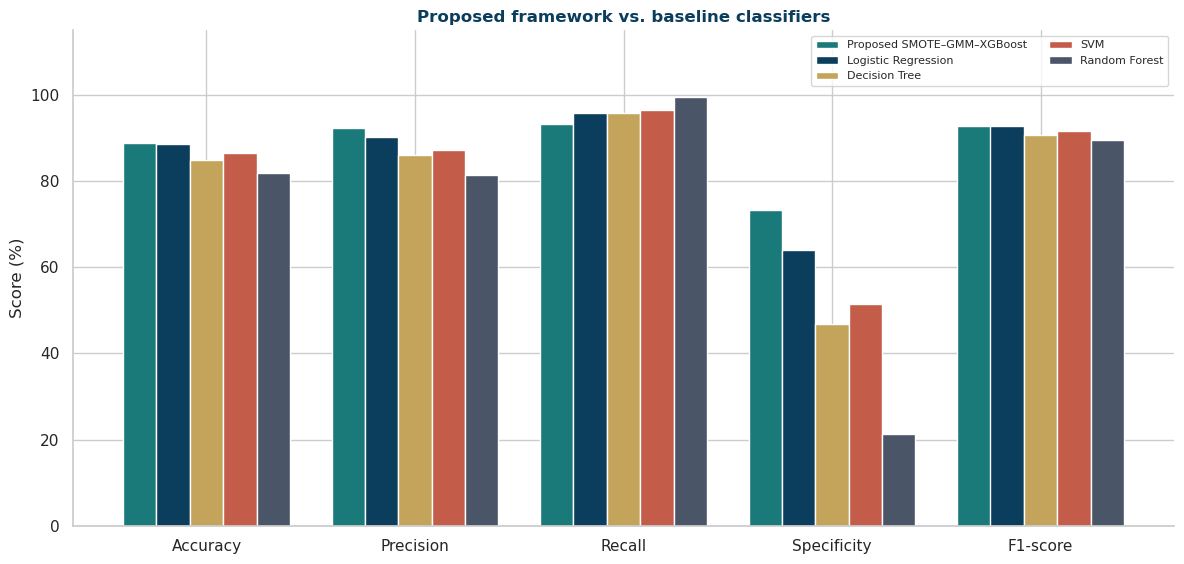

In [60]:
comparison_metrics = ["Accuracy", "Precision", "Recall", "Specificity", "F1-score"]
model_names = list(all_metrics.keys())
x_positions = np.arange(len(comparison_metrics))
bar_width = 0.16
comparison_colors = [TEAL, NAVY, GOLD, CORAL, SLATE]

fig, ax = plt.subplots(figsize=(12, 5.8))
for index, model_name in enumerate(model_names):
    values_pct = [100 * all_metrics[model_name][metric] for metric in comparison_metrics]
    offset = (index - (len(model_names) - 1) / 2) * bar_width
    ax.bar(
        x_positions + offset,
        values_pct,
        bar_width,
        label=model_name,
        color=comparison_colors[index % len(comparison_colors)],
        edgecolor="white",
    )

ax.set_xticks(x_positions)
ax.set_xticklabels(comparison_metrics)
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 115)
ax.set_title("Proposed framework vs. baseline classifiers", color=NAVY, fontweight="bold")
ax.legend(fontsize=8, ncol=2, loc="upper right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

## 17. Final results table

In [61]:
final_results = metrics_comparison.copy() * 100
final_results.columns = [f"{column} (%)" for column in final_results.columns]
display(final_results.round(2))

,Accuracy (%),Precision (%),Recall (%),Specificity (%),F1-score (%),ROC-AUC (%)
Proposed SMOTE–GMM–XGBoost,88.81,92.35,93.30,73.37,92.82,90.93
Logistic Regression,88.55,90.13,95.70,63.91,92.83,91.67
Decision Tree,84.82,86.11,95.88,46.75,90.73,84.45
SVM,86.42,87.27,96.56,51.48,91.68,90.43
Random Forest,81.89,81.32,99.48,21.30,89.49,89.80
